# Mount Google Drive and Link Datasets

In [ ]:
rm -rf /content/data

In [ ]:
# Create base data directory
!mkdir -p /content/data

# 3. Link the *inner* ISIC2019_merged folder directly (the one that contains 7 class folders)
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged" /content/data/ISIC2019

# 4. Link the unlabeled Fitzpatrick target domain
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/dummy" /content/data/Fitzpatrick17k

# 5. Link the labeled Fitzpatrick test subset
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected" /content/data/Fitzpatrick17k_test


In [ ]:
!rm -rf /content/data/ISIC2019/ISIC2019_merged
!rm -rf /content/data/Fitzpatrick17k/dummy
!rm -rf /content/data/Fitzpatrick17k_test/fitz_selected

In [ ]:
# -------------------------
# Clean install for PyTorch + DA
# -------------------------

!pip install --upgrade pip
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

# Basic deps
!pip install numpy scipy tqdm pandas scikit-learn matplotlib seaborn

# Image processing
!pip install pillow opencv-python

# Optional but recommended
!pip install albumentations

# Debug utilities (optional)
!pip install rich supervision


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 78.0 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
Looking in indexes: https://download.pytorch.org/whl/cu118


In [ ]:
import torch
import torchvision

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Torch: 2.9.0+cu126
Torchvision: 0.24.0+cu126
CUDA available: True
Device: Tesla T4


# Install Dependencies

In [ ]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install scikit-learn pandas tqdm matplotlib seaborn


Looking in indexes: https://download.pytorch.org/whl/cu118


# Run ADDA Training

In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation


/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
SOURCE = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged"
TARGET = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/dummy"
TEST   = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"

In [ ]:
!python "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/attention_adda_mobilenetv2.py" \
  --source-dir "$SOURCE" \
  --target-dir "$TARGET" \
  --test-dir "$TEST" \
  --out-dir "/content/drive/MyDrive/Colab Results/ADDA_TADA_MOBILENETV2" \
  --batch-size 16 \
  --pretrain-epochs 20 \
  --adapt-epochs 40 \
  --use-focal \
  --gamma-ent 0.1 \
  --lambda-adv 1.0


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
>>> Pretraining source encoder + classifier
Pretrain Ep 1/20: 100% 1567/1567 [02:38<00:00,  9.88it/s, acc=0.683, loss=0.144]
Pretrain epoch 1 loss=0.1186 acc=0.6834
Pretrain Ep 2/20: 100% 1567/1567 [02:16<00:00, 11.49it/s, acc=0.741, loss=0.0698]
Pretrain epoch 2 loss=0.0887 acc=0.7407
Pretrain Ep 3/20: 100% 1567/1567 [02:16<00:00, 11.51it/s, acc=0.767, loss=0.0336]


# View Evaluation Results

,precision,recall,f1-score,support
ak,0.117647,0.057143,0.076923,175.000000
bcc,0.265781,0.160000,0.199750,500.000000
bkl,0.020134,0.043478,0.027523,69.000000
df,0.000000,0.000000,0.000000,79.000000
mel,0.287162,0.170000,0.213568,500.000000
nv,0.066775,0.347458,0.112022,236.000000
scc,0.000000,0.000000,0.000000,500.000000
accuracy,0.126275,0.126275,0.126275,0.126275
macro avg,0.108214,0.111154,0.089969,2059.000000
weighted avg,0.152602,0.126275,0.120669,2059.000000


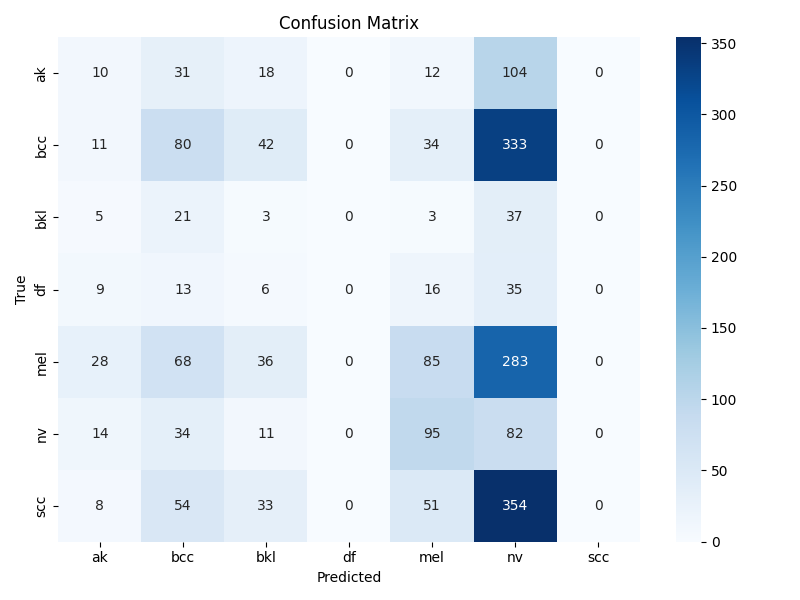

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Load classification report
report_path = "/content/drive/MyDrive/Colab Results/ADDA_TADA_MOBILENETV2/classification_report.csv"
df = pd.read_csv(report_path, index_col=0)
display(df)

# Show confusion matrix
cm_path = "/content/drive/MyDrive/Colab Results/ADDA_TADA_MOBILENETV2/confusion_matrix.png"
display(Image(filename=cm_path))
